# 다이아몬드 EDA

**EDA** = 모델 전에 데이터를 그림·표로 살펴보는 일입니다.  
가격(**price**)을 맞추려면, 먼저 힌트 칸이 어떻게 생겼는지 봅니다.


In [2]:
# 숫자 표·그림 도구 불러오기
# seaborn = 예쁜 통계 그림을 쉽게 그리는 도구
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
# seaborn에 들어 있는 diamonds 표 불러오기 (파일 경로 쓰지 않음)
df = sns.load_dataset("diamonds")

print("shape:", df.shape)
print(df.head())
print("dtypes:\n", df.dtypes)



shape: (53940, 10)
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
dtypes:
 carat       float64
cut        category
color      category
clarity    category
depth       float64
table       float64
price         int64
x           float64
y           float64
z           float64
dtype: object


## 분포 보기

**히스토그램** = 값이 어디에 몰렸는지 막대로 봅니다.  
**박스플롯** = 가운데·수염·튀는 점을 한눈에 봅니다.


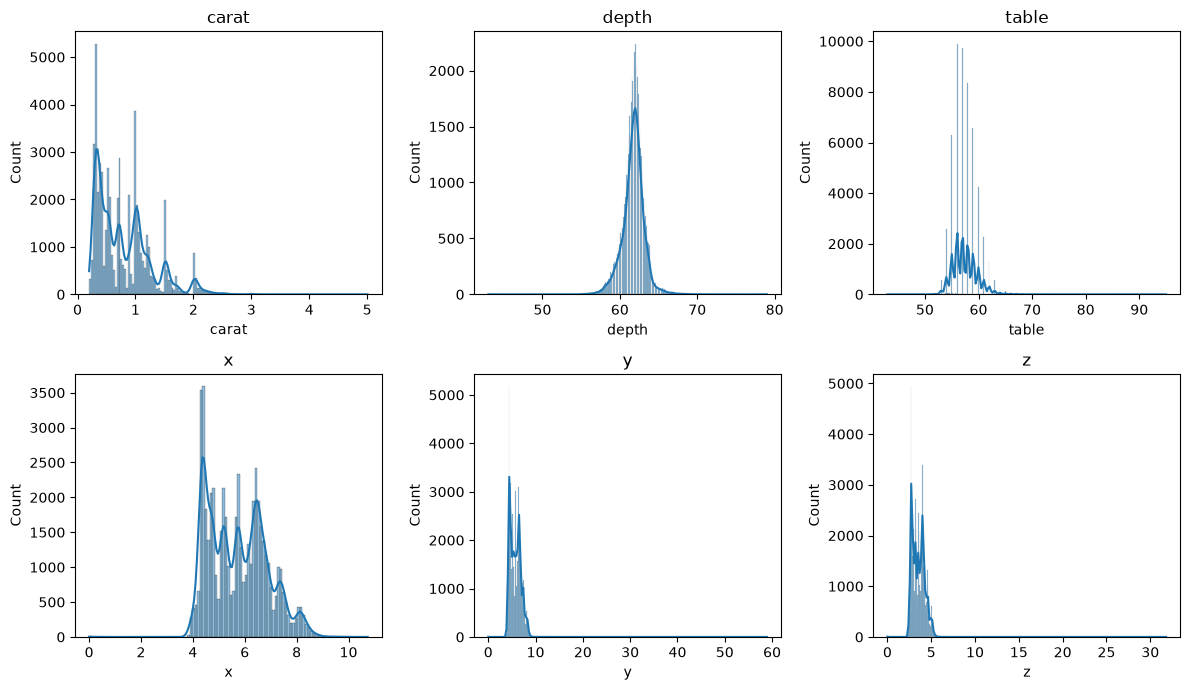

수치형 histplot(+kde) 완료: ['carat', 'depth', 'table', 'x', 'y', 'z']


In [4]:
# 숫자 칸별 분포 그림(막대 + 부드러운 곡선)
num_cols = ["carat", "depth", "table", "x", "y", "z"]

# subplots = 작은 그림판을 2줄 3칸으로 만들기
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
# ravel = 2줄 배열을 한 줄 목록으로 펴기
axes = axes.ravel()

# zip = 그림판과 칸 이름을 짝지어 하나씩 그림
for ax, col in zip(axes, num_cols):
    # histplot = 값 분포 막대. kde=True = 부드러운 곡선도 같이
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(col)

# tight_layout = 그림끼리 안 겹치게 간격 맞춤
plt.tight_layout()
plt.show()
print("수치형 histplot(+kde) 완료:", num_cols)



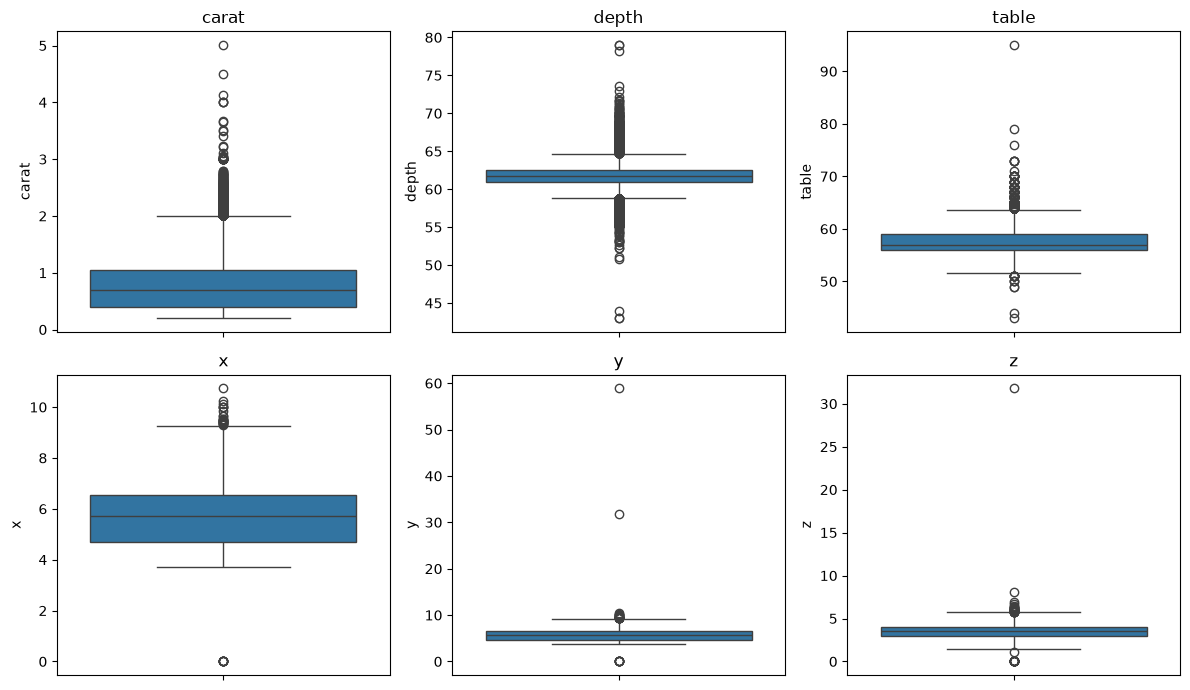

수치형 boxplot 완료: ['carat', 'depth', 'table', 'x', 'y', 'z']


In [5]:
# 같은 칸을 상자 그림으로도 보기
# boxplot = 가운데·퍼짐·튀는 값을 상자로 보여 줌
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()
print("수치형 boxplot 완료:", num_cols)



## 이상치와 IQR

**이상치** = 다른 값과 너무 동떨어진 숫자입니다.  
**IQR** = 가운데 절반의 폭(Q3−Q1). 폭의 1.5배 밖을 튀는 값으로 자주 봅니다.


In [6]:
# IQR = 가운데 50% 폭. 그 1.5배 밖 값은 이상치로 빼고 거름
def filter_iqr(frame, cols, multiplier=1.5):
    """각 컬럼의 Q1±1.5*IQR 밖 행을 제거한 DataFrame 반환"""
    # mask = 남길 줄인지 표시(처음엔 전부 남김)
    mask = pd.Series(True, index=frame.index)
    for col in cols:
        # Q1 = 아래쪽 25% 지점, Q3 = 위쪽 25% 지점
        q1 = frame[col].quantile(0.25)
        q3 = frame[col].quantile(0.75)
        iqr = q3 - q1
        # 이 범위 밖이면 이상치로 봄
        lower = q1 - multiplier * iqr
        upper = q3 + multiplier * iqr
        # between = 범위 안인 줄만 True. &= 로 칸마다 조건을 겹침
        mask &= frame[col].between(lower, upper)
    # loc[mask] = True인 줄만 남긴 새 표
    return frame.loc[mask].copy()

before = len(df)
df_iqr = filter_iqr(df, num_cols, multiplier=1.5)
after = len(df_iqr)

print(f"IQR 제거 전 행 수: {before}")
print(f"IQR 제거 후 행 수: {after}")
print(f"제거된 행 수: {before - after}")
# 참고: 행이 약 53940 → 48898 근처로 줄어들 수 있음



IQR 제거 전 행 수: 53940
IQR 제거 후 행 수: 49304
제거된 행 수: 4636


price와의 상관(수치형):
carat    0.921591
x        0.884435
y        0.865421
z        0.861249
table    0.127134
depth   -0.010647
Name: price, dtype: float64


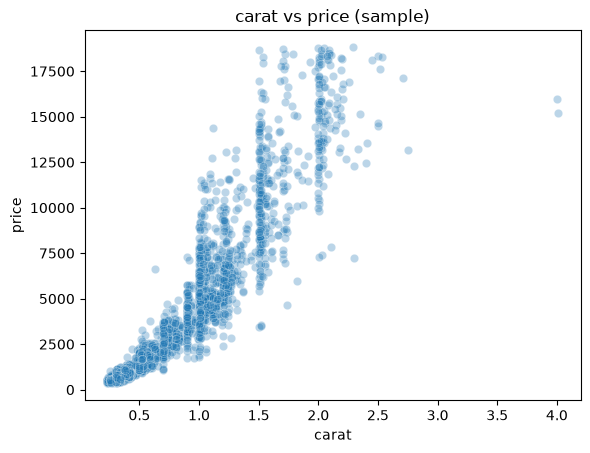

In [7]:
# (선택) price와 숫자 칸의 상관 = 같이 움직이는 정도
# corr = 칸끼리 같이 움직이는 정도(-1~1). price와의 관계만 뽑아 정렬
corr_price = df[num_cols + ["price"]].corr()["price"].drop("price").sort_values(ascending=False)
print("price와의 상관(수치형):")
print(corr_price)

# carat과 price를 점으로 한 장 그리기
# sample = 점이 너무 많아 일부만 뽑아 그림
sns.scatterplot(data=df.sample(n=min(3000, len(df)), random_state=42), x="carat", y="price", alpha=0.3)
plt.title("carat vs price (sample)")
plt.show()

